## Import relevant libraries

In [1]:
from pathlib import Path
import ezdxf
from collections import Counter
import pandas as pd
from helpers_revised import *

## Plot DXF files

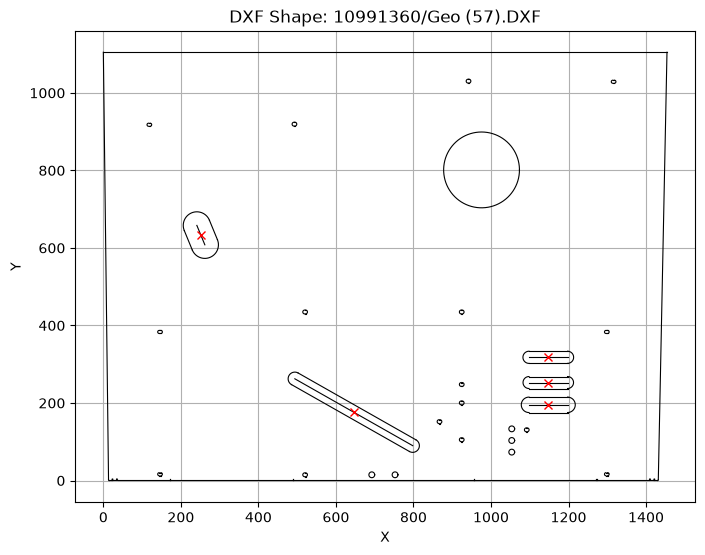

In [2]:
plot_dxf("10991360/Geo (57).DXF")

## Find out where the points are located

In [4]:
for f in Path("../Challenge1/10991360").glob("*.[dD][xX][fF]"):
    if get_point_context(f) != []:
        print(f, ": ", get_point_context(f))

../Challenge1/10991360/Geo (23).DXF :  [1, 1, 1, 1, 1, 1]
../Challenge1/10991360/Geo (9).DXF :  [1, 1]
../Challenge1/10991360/Geo (78).DXF :  [1]
../Challenge1/10991360/Geo (14).DXF :  [1, 1]
../Challenge1/10991360/Geo (13).DXF :  [1]
../Challenge1/10991360/Geo (25).DXF :  [1, 1, 1, 1, 1]
../Challenge1/10991360/Geo (64).DXF :  [1, 1, 1, 1]
../Challenge1/10991360/Geo (65).DXF :  [1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
../Challenge1/10991360/Geo (53).DXF :  [1]
../Challenge1/10991360/Geo (12).DXF :  [1, 1]
../Challenge1/10991360/Geo (11).DXF :  [1, 1, 1, 1, 1, 1]
../Challenge1/10991360/Geo (66).DXF :  [1, 1, 1, 1, 1, 1, 1]
../Challenge1/10991360/Geo (71).DXF :  [1]
../Challenge1/10991360/Geo (10).DXF :  [1, 1, 1, 1, 1]
../Challenge1/10991360/Geo (7).DXF :  [1, 1, 1]
../Challenge1/10991360/Geo (57).DXF :  [1, 1, 1, 1, 1]
../Challenge1/10991360/Geo (6).DXF :  [1, 1]


## Count the different object types in the DXF-dataset

In [3]:
total = Counter()
for f in Path("../Challenge1/10991360").glob("*.[dD][xX][fF]"):   # glob ist case-sensitive, bei .DXF ggf. "*.[dD][xX][fF]"
    try:
        msp = ezdxf.readfile(f).modelspace()
        total.update(e.dxftype() for e in msp)
    except Exception as ex:
        print(f"Fehler bei {f.name}: {ex}")

print(total)

Counter({'LINE': 1814, 'CIRCLE': 530, 'ARC': 491, 'POINT': 63})


## Print object types for every DXF-file containing points

In [5]:
for f in Path("../Challenge1/10991360").glob("*.[dD][xX][fF]"):
    msp = ezdxf.readfile(f).modelspace()
    c = Counter(e.dxftype() for e in msp)
    if c["POINT"]:
        print(f.name, dict(c))

Geo (23).DXF {'ARC': 18, 'LINE': 52, 'POINT': 6}
Geo (9).DXF {'ARC': 10, 'CIRCLE': 4, 'LINE': 16, 'POINT': 2}
Geo (78).DXF {'ARC': 6, 'CIRCLE': 51, 'LINE': 11, 'POINT': 1}
Geo (14).DXF {'ARC': 27, 'LINE': 38, 'POINT': 2}
Geo (13).DXF {'ARC': 6, 'CIRCLE': 2, 'LINE': 13, 'POINT': 1}
Geo (25).DXF {'ARC': 27, 'CIRCLE': 5, 'LINE': 30, 'POINT': 5}
Geo (64).DXF {'CIRCLE': 8, 'ARC': 8, 'LINE': 102, 'POINT': 4}
Geo (65).DXF {'ARC': 22, 'LINE': 34, 'POINT': 10}
Geo (53).DXF {'CIRCLE': 6, 'ARC': 4, 'LINE': 41, 'POINT': 1}
Geo (12).DXF {'CIRCLE': 9, 'ARC': 4, 'LINE': 16, 'POINT': 2}
Geo (11).DXF {'ARC': 32, 'LINE': 42, 'POINT': 6}
Geo (66).DXF {'ARC': 20, 'LINE': 35, 'POINT': 7}
Geo (71).DXF {'CIRCLE': 1, 'ARC': 3, 'LINE': 10, 'POINT': 1}
Geo (10).DXF {'ARC': 14, 'LINE': 25, 'POINT': 5}
Geo (7).DXF {'ARC': 6, 'LINE': 13, 'POINT': 3}
Geo (57).DXF {'CIRCLE': 6, 'ARC': 44, 'LINE': 87, 'POINT': 5}
Geo (6).DXF {'ARC': 12, 'CIRCLE': 2, 'LINE': 25, 'POINT': 2}


## Test if POINTS are marker for centers of circles

In [6]:
for name in ["10991360/Geo (65).DXF", "10991360/Geo (78).DXF", "10991360/Geo (13).DXF"]:
    msp = ezdxf.readfile(name).modelspace()
    circles = [(c.dxf.center.x, c.dxf.center.y) for c in msp.query("CIRCLE")]
    print(name)
    for p in msp.query("POINT"):
        x, y = p.dxf.location.x, p.dxf.location.y
        d = min((((x - cx)**2 + (y - cy)**2) ** 0.5 for cx, cy in circles), default=None)
        print(f"  layer={p.dxf.layer} pos=({x:.2f}, {y:.2f}) Abstand zum nächsten Kreismittelpunkt: {d}")

10991360/Geo (65).DXF
  layer=0 pos=(39.70, 65.75) Abstand zum nächsten Kreismittelpunkt: None
  layer=0 pos=(116.85, 71.85) Abstand zum nächsten Kreismittelpunkt: None
  layer=0 pos=(212.48, 78.22) Abstand zum nächsten Kreismittelpunkt: None
  layer=0 pos=(310.47, 67.81) Abstand zum nächsten Kreismittelpunkt: None
  layer=0 pos=(391.05, 61.55) Abstand zum nächsten Kreismittelpunkt: None
  layer=0 pos=(487.54, 54.74) Abstand zum nächsten Kreismittelpunkt: None
  layer=0 pos=(576.94, 64.46) Abstand zum nächsten Kreismittelpunkt: None
  layer=0 pos=(697.71, 62.75) Abstand zum nächsten Kreismittelpunkt: None
  layer=0 pos=(752.72, 75.29) Abstand zum nächsten Kreismittelpunkt: None
  layer=0 pos=(815.90, 62.79) Abstand zum nächsten Kreismittelpunkt: None
10991360/Geo (78).DXF
  layer=0 pos=(351.03, 143.89) Abstand zum nächsten Kreismittelpunkt: 48.770753046099905
10991360/Geo (13).DXF
  layer=0 pos=(88.11, 22.88) Abstand zum nächsten Kreismittelpunkt: 71.70466060645266
